In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Plot-only notebook: the numbers are produced by `python postprocess.py` (-> ./data/*.csv)
os.makedirs('../plots', exist_ok=True)

In [2]:
df = pd.read_csv('data/model_acc_plot.csv')
acc = df.set_index(['leakage', 'traces_k'])

In [3]:
numTraces = [2, 3, 4, 5, 6, 7, 10, 20]
leak_mod_models_acc = [[acc.loc[(leak_mod, k), 'acc_raw'] for k in numTraces] for leak_mod in ['HD', 'HW']]

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import MultipleLocator
from matplotlib.lines import Line2D

def plot_model_accuracy(trace_nums, accuracies, series_labels,
                               save_name='extracted_acc_single',
                               xlabel='Number of Traces Used',
                               ylabel='Model Accuracy',
                               title='',
                               figsize=(8, 6),
                               baseline=0.8445,
                               font_size=40):
    """
    Plot model accuracy without splitting into left/right axes.
    """
    sns.set(style="whitegrid", rc={ 'font.size': font_size,
                                    'axes.titlesize' : font_size,
                                    'axes.labelsize' : font_size,
                                     'xtick.labelsize' : font_size,
                                     'ytick.labelsize' : font_size,
                                     'legend.fontsize' : font_size})



    x = np.asarray(trace_nums, dtype=float)
    fig, ax = plt.subplots(figsize=figsize)

    # plot each accuracy series
    for acc, lbl in zip(accuracies, series_labels):
        ax.plot(x, acc, marker='o', linewidth=1.5, markersize=16, label=lbl)

    # baseline
    ax.axhline(baseline, linestyle='--', color='black', label=f'Baseline')

    # axis labels, ticks, grid
    ax.set_ylim(0, 1)
    ax.yaxis.set_major_locator(MultipleLocator(0.1))
    ax.set_ylabel(ylabel)
    ax.set_xlabel(xlabel)
    ax.grid(True)

    # x ticks as “k”
    ax.set_xticks(x)
    ax.set_xticklabels([f'{int(v) if int(v) == v else v}k' for v in x]
                    , rotation=45)
    ax.tick_params(axis='y')

    # title and legend
    ax.set_title(title)
    ax.legend(loc='best', frameon=True)

    plt.tight_layout()
    fig.savefig(f"../plots/{save_name}.pdf", format="pdf",
                bbox_inches="tight", metadata={"Creator": "Matplotlib"})
    plt.show()

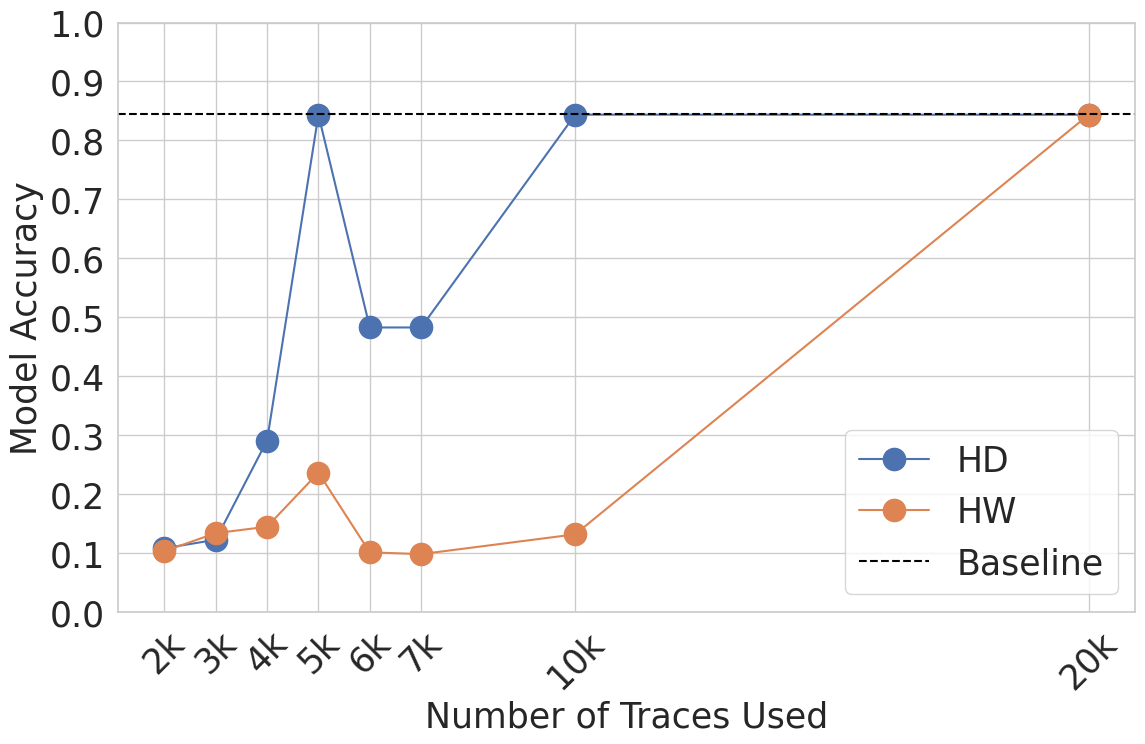

In [5]:
plot_model_accuracy(numTraces, [leak_mod_models_acc[0], leak_mod_models_acc[1]], ['HD', 'HW'], figsize=(12, 8), font_size=25)

Fix the dip

In [6]:
# sign-flip fix of the last layer (rows of classes with <10% accuracy), see postprocess.sign_fix
inputDistAccAfterFlipLeskMod = [[acc.loc[(leak_mod, k), 'acc_sign_fixed'] for k in numTraces] for leak_mod in ['HD', 'HW']]

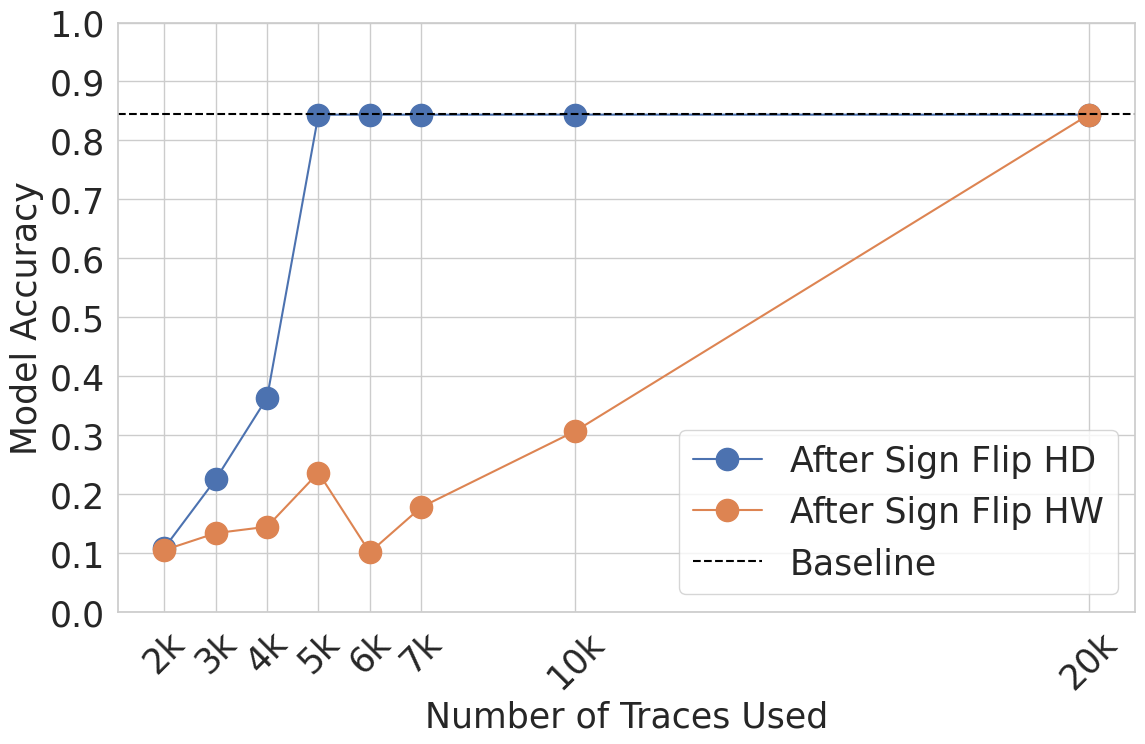

In [7]:
plot_model_accuracy(numTraces, [inputDistAccAfterFlipLeskMod[0], inputDistAccAfterFlipLeskMod[1]], ['After Sign Flip HD', 'After Sign Flip HW'], figsize=(12, 8), font_size=25, save_name='extracted_acc')

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import MultipleLocator

def plot_model_accuracy(trace_nums, accuracies, series_labels,
                        dashed_accuracies=None, dashed_labels=None,
                        save_name='extracted_acc',
                        xlabel='Number of Traces Used',
                        ylabel='Model Accuracy',
                        title='',
                        figsize=(8, 6),
                        baseline=0.8445,
                        font_size=40,
                        linewidth=2.0,
                        markersize=16,
                        main_marker='o',
                        dashed_markers=None,          # NEW: markers for dashed/comparison series
                        baseline_linestyle='--',
                        baseline_label='Baseline'):
    """
    Same input layout as your original function.

    Change requested:
      - Do NOT distinguish by line style (solid vs dashed).
      - Distinguish the "dashed_accuracies" series by MARKER SHAPE instead.
      - Colors still match between main and its comparison series.
    """

    # If no dashed lines provided, make empty lists
    if dashed_accuracies is None:
        dashed_accuracies = []
    if dashed_labels is None:
        dashed_labels = []

    # Ensure lengths match
    assert len(dashed_accuracies) == len(dashed_labels), \
        "dashed_accuracies and dashed_labels must have same length"

    # Default marker shapes for the "dashed"/comparison series
    if dashed_markers is None:
        dashed_markers = ["s", "^", "D", "v", "P", "X", "*", "<", ">", "h", "H", "p", "8", "+", "x"]

    # --------------------------------------------------------------
    #  STYLE SETTINGS
    # --------------------------------------------------------------
    sns.set(style="whitegrid", rc={
        'font.size': font_size,
        'axes.titlesize': font_size,
        'axes.labelsize': font_size,
        'xtick.labelsize': font_size,
        'ytick.labelsize': font_size,
        'legend.fontsize': font_size - 2
    })

    x = np.asarray(trace_nums, dtype=float)
    fig, ax = plt.subplots(figsize=figsize)

    # --------------------------------------------------------------
    #  COLORS (store them so comparison lines match exactly)
    # --------------------------------------------------------------
    color_cycle = plt.rcParams['axes.prop_cycle'].by_key()['color']

    # --------------------------------------------------------------
    #  MAIN LINES + "DASHED" COMPARISON (marker-shape instead)
    # --------------------------------------------------------------
    for i, (acc, lbl) in enumerate(zip(accuracies, series_labels)):
        color = color_cycle[i % len(color_cycle)]

        # Main series (solid line)
        ax.plot(
            x, acc,
            marker=main_marker,
            linewidth=linewidth,
            markersize=markersize,
            label=lbl,
            color=color
        )

        # Comparison series (same line style; different MARKER shape)
        if i < len(dashed_accuracies) and dashed_accuracies[i] is not None and len(dashed_accuracies[i]) > 0:
            cmp_marker = dashed_markers[i % len(dashed_markers)]
            ax.plot(
                x, dashed_accuracies[i],
                linestyle='-',              # IMPORTANT: not dashed
                marker=cmp_marker,          # DIFFERENT SHAPE
                linewidth=linewidth,
                markersize=markersize,
                label=dashed_labels[i],
                color=color
            )

    # --------------------------------------------------------------
    # BASELINE
    # --------------------------------------------------------------
    ax.axhline(baseline, linestyle=baseline_linestyle, color='black', label=baseline_label)

    # --------------------------------------------------------------
    # AXES CONFIG
    # --------------------------------------------------------------
    ax.set_ylim(0, 1)
    ax.yaxis.set_major_locator(MultipleLocator(0.1))
    ax.set_ylabel(ylabel)
    ax.set_xlabel(xlabel)
    ax.grid(True)

    # x ticks in "k"
    ax.set_xticks(x)
    ax.set_xticklabels([f'{int(v) if float(v).is_integer() else v}k' for v in x], rotation=45)

    ax.set_title(title)
    ax.legend(loc='best', frameon=True)

    plt.tight_layout()
    fig.savefig(f"../plots/{save_name}.pdf", format="pdf",
                bbox_inches="tight", metadata={"Creator": "Matplotlib"})
    plt.show()
    return fig, ax

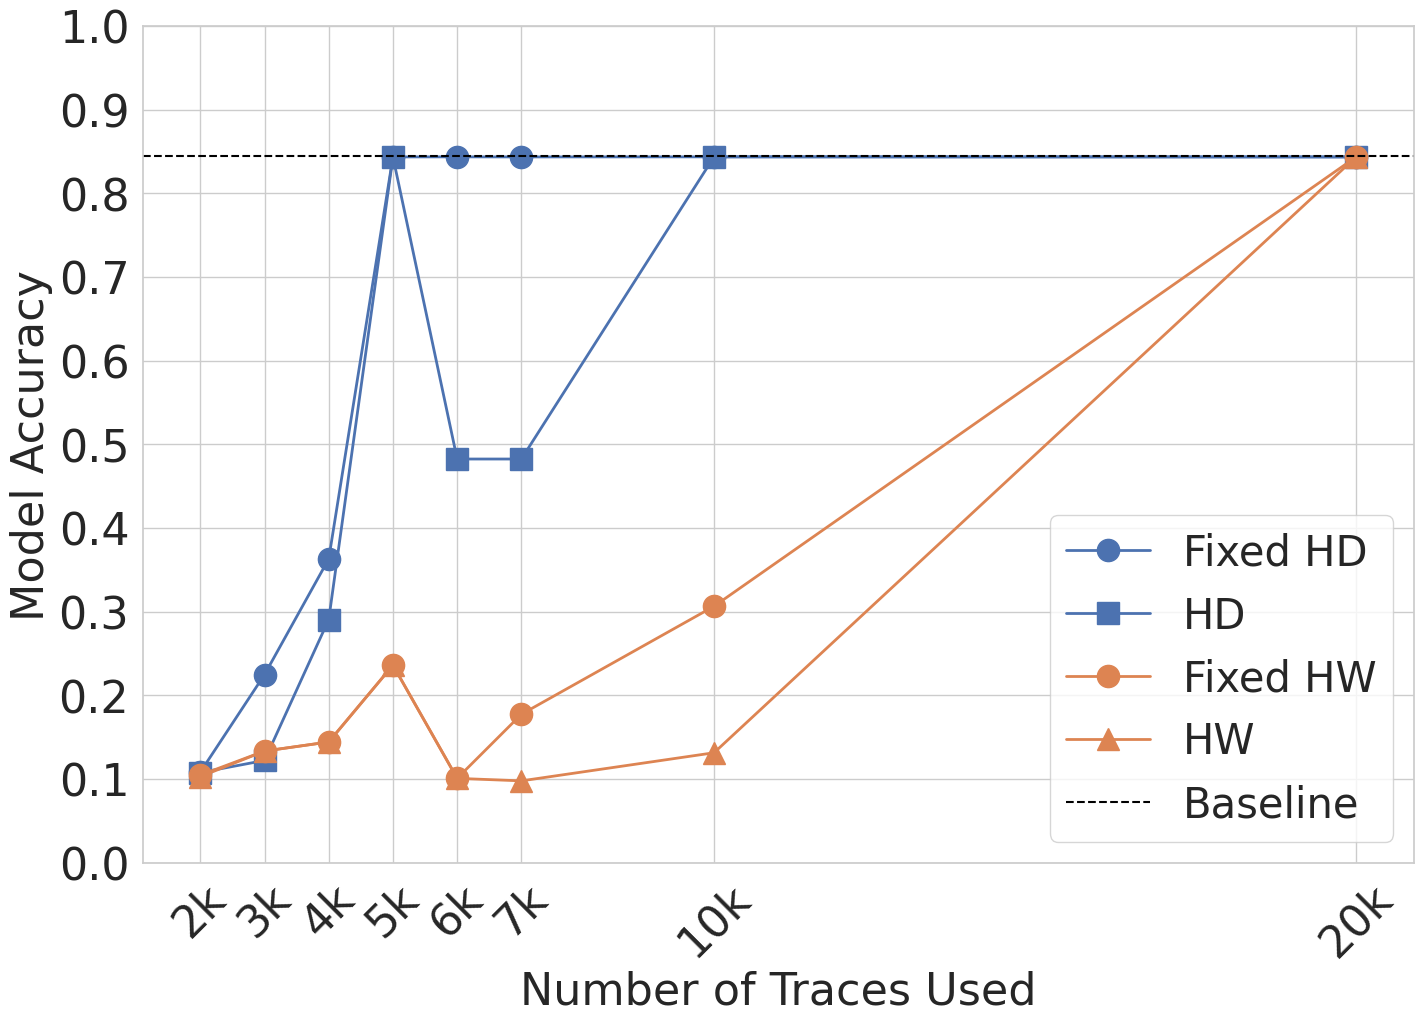

(<Figure size 1500x1100 with 1 Axes>,
 <Axes: xlabel='Number of Traces Used', ylabel='Model Accuracy'>)

In [9]:
plot_model_accuracy(
    trace_nums=numTraces,
    accuracies=[inputDistAccAfterFlipLeskMod[0], inputDistAccAfterFlipLeskMod[1]],
    series_labels= ['Fixed HD', 'Fixed HW'],

    dashed_accuracies=[leak_mod_models_acc[0], leak_mod_models_acc[1]],
    dashed_labels=['HD', 'HW'],

    figsize=(15, 11), font_size=32, save_name='extracted_acc'
)